## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from datasets.code.helper import get_altimetry_obs, get_wl_point_obs, get_u_v_point_obs

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager

## Load Data

In [3]:
# folders
dfs_fldr = "datasets/output_sample/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

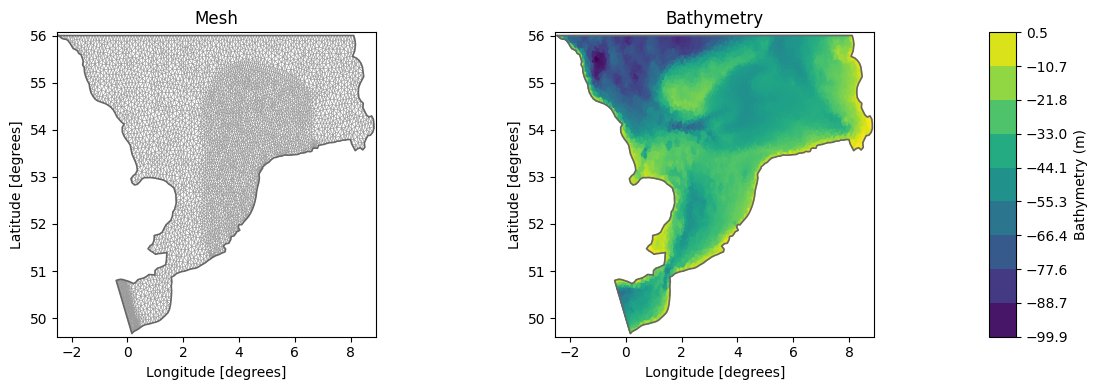

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

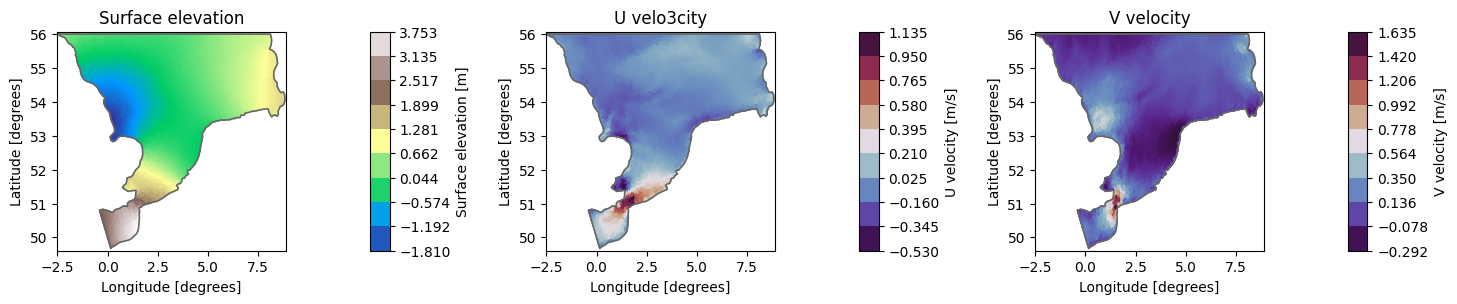

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


<Axes: >

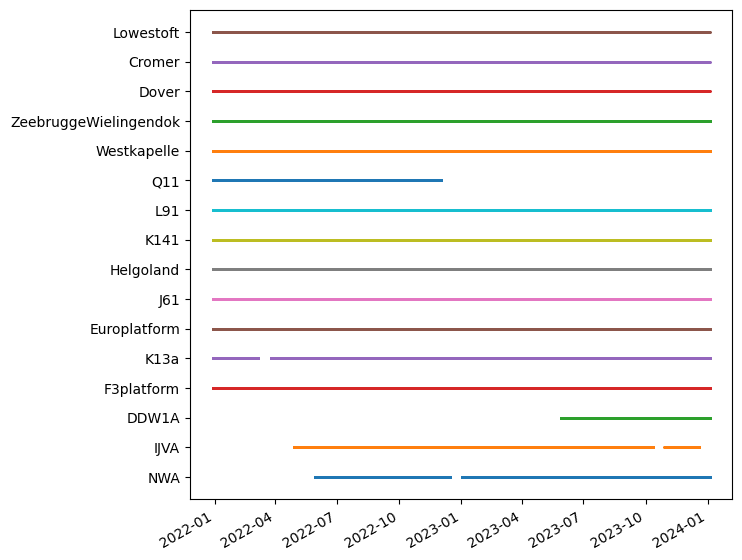

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
ms.plotting.temporal_coverage(wllist)

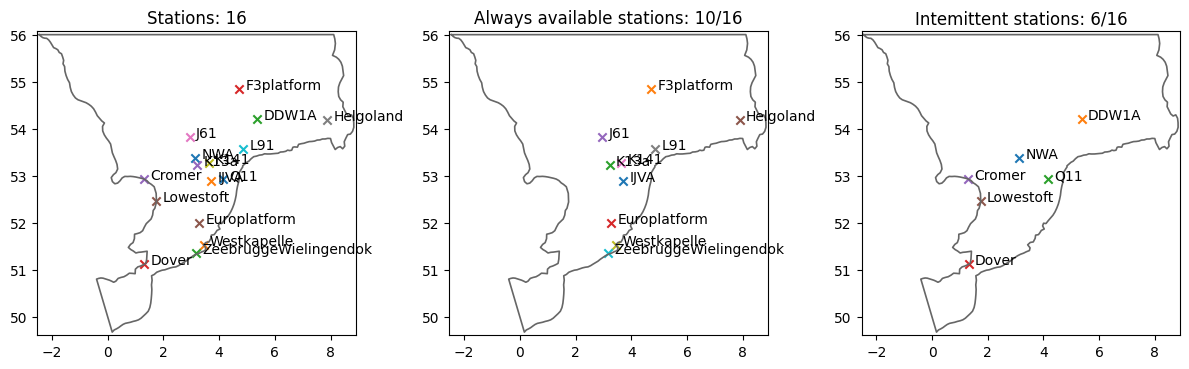

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = np.full((ds.time.shape[0], len(stations)), np.nan)

for i in range(len(stations)):
    
    stn_data = pd.read_csv(obs_fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"].reindex(ds.time.strftime("%Y-%m-%d %H:%M:%S")).values 

In [9]:
# Extract the values and convert to torch tensors

# outputs
H = torch.tensor(dsH.values, dtype=torch.float32)
U = torch.tensor(dsU.values, dtype=torch.float32)
V = torch.tensor(dsV.values, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

H shape: torch.Size([337, 8566])
U shape: torch.Size([337, 8566])
V shape: torch.Size([337, 8566])
Measurements shape: torch.Size([337, 16])


## Idea 0: Only Available Sensors

In [10]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)

print("Available stations:", [s.name for s in availables])

H shape: torch.Size([337, 8566])
U shape: torch.Size([337, 8566])
V shape: torch.Size([337, 8566])
Measurements shape: torch.Size([337, 10])
Available stations: ['IJVA', 'F3platform', 'K13a', 'Europlatform', 'J61', 'Helgoland', 'K141', 'L91', 'Westkapelle', 'ZeebruggeWielingendok']


In [11]:
#counts nans
nan_counts = np.isnan(measurements_av).sum(axis=0)
print("NaN counts for each station:", nan_counts)

NaN counts for each station: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [12]:
# Data manager

manager = DataManager(
    lags = 48, # 1 day of past measurements for predictions 
    train_size = 0.8,
    val_size = 0.1,
    test_size = 0.1
)

manager.add_data(
    data = H,
    id = "Surface elevation",
    measurements = measurements_av,
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = U,
    id = "U velocity",
    compress = 100 # 100 POD modes for compressive training 
)

manager.add_data(
    data = V,
    id = "V velocity",
    compress = 100 # 100 POD modes for compressive training 
)

train_dataset, val_dataset, test_dataset= manager.prepare()


ValueError: Input contains NaN.